## How to run in Colab
1. Open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → choose this file.
2. The datasets: `Daily Temperature US Cities 2015-2019.zip` is already in `C:\Users\sivan\Datasets` (made from [Kaggle – Daily Temperature of Major Cities](https://www.kaggle.com/datasets/sudalairajkumar/daily-temperature-of-major-cities)). It is a small part: US cities in California, Texas and New York, 2015–2019. And `Wine Price on Polish Market.zip` is already in `C:\Users\sivan\Datasets` (made from [Kaggle – Wine Price on Polish Market](https://www.kaggle.com/datasets/skamlo/wine-price-on-polish-market)).
3. There are two upload cells: in the first choose `Daily Temperature US Cities 2015-2019.zip`, in the second (before Exercise 4) choose `Wine Price on Polish Market.zip`, both from `C:\Users\sivan\Datasets`.

**Run the cells from top to bottom** (Shift+Enter runs one cell). After a restart, run them again from the top.

# Week 2 Day 4 – Exercises XP Ninja: Data Visualization

## 👩‍🏫 👩🏿‍🏫 What You’ll learn
- Advanced visualization for multi-dimensional and hierarchical data.
- Interactive Python code for dynamic plot generation.
- Machine learning models for prediction and analysis.
- Clustering techniques to identify patterns.
- Matplotlib, Seaborn and Scikit-learn for data exploration.

## Datasets
- `city_temperature_us_2015_2019.csv` – daily average temperatures of US cities (°F; `-99` means “no measurement”).
- `wine.csv` – wines sold in Poland: price (PLN), country, vintage, alcohol %.

## Setup

In [1]:
import pandas as pd
# pandas: tables
import numpy as np
# numpy: math on arrays
import matplotlib.pyplot as plt
# matplotlib: charts
import seaborn as sns
# seaborn: statistical charts
sns.set_theme(style='whitegrid')
# a clean seaborn style for all charts

In [ ]:
from google.colab import files
# the Colab tool for uploading files from your computer
uploaded = files.upload()
# choose "Daily Temperature US Cities 2015-2019.zip" (saved in a variable so its contents are not printed)
!unzip "Daily Temperature US Cities 2015-2019.zip"
# unzip it: you get the file "city_temperature_us_2015_2019.csv"

In [2]:
temps = pd.read_csv('city_temperature_us_2015_2019.csv')
# read the temperature file
temps = temps[temps['AvgTemperature'] != -99]
# remove the rows where the temperature is missing (-99)
temps['Date'] = pd.to_datetime(temps[['Year', 'Month', 'Day']])
# build one real date column from the Year, Month and Day columns
temps['Temp_C'] = ((temps['AvgTemperature'] - 32) * 5 / 9).round(1)
# convert °F to °C
temps.head()
# first rows

,Region,Country,State,City,Month,Day,Year,AvgTemperature,Date,Temp_C
0,North America,US,California,Fresno,1,1,2015,38.2,2015-01-01,3.4
1,North America,US,California,Fresno,1,2,2015,38.9,2015-01-02,3.8
2,North America,US,California,Fresno,1,3,2015,39.9,2015-01-03,4.4
3,North America,US,California,Fresno,1,4,2015,41.6,2015-01-04,5.3
4,North America,US,California,Fresno,1,5,2015,43.6,2015-01-05,6.4


---
# Exercise 1: Annotated Line Graph for Temperature Records
**Objective:** Line graph of temperatures in one city, with the extreme days annotated, titles, labels and a legend. We use **New York City in 2019**.

In [3]:
nyc = temps[(temps['City'] == 'New York City') & (temps['Year'] == 2019)]
# keep only New York City in 2019
hottest = nyc.loc[nyc['Temp_C'].idxmax()]
# the row of the hottest day (idxmax = index of the biggest value)
coldest = nyc.loc[nyc['Temp_C'].idxmin()]
# the row of the coldest day
print('Hottest:', hottest['Date'].date(), hottest['Temp_C'], '°C')
# show the hottest day
print('Coldest:', coldest['Date'].date(), coldest['Temp_C'], '°C')
# show the coldest day

Hottest: 2019-07-21 33.4 °C
Coldest: 2019-01-31 -12.6 °C


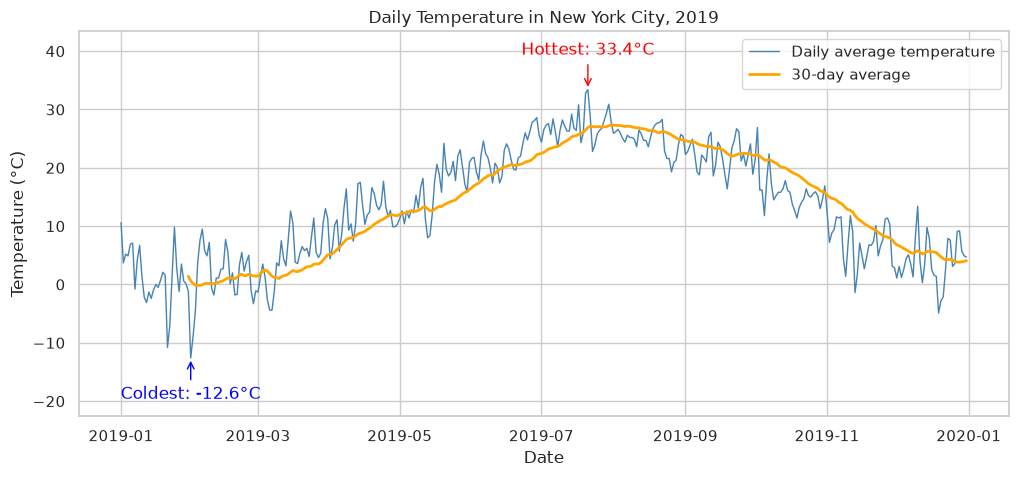

In [4]:
plt.figure(figsize=(12, 5))
# a wide chart
plt.plot(nyc['Date'], nyc['Temp_C'], color='steelblue', linewidth=1, label='Daily average temperature')
# the daily temperature line
plt.plot(nyc['Date'], nyc['Temp_C'].rolling(30).mean(), color='orange', linewidth=2, label='30-day average')
# a smoother line: average of the last 30 days
plt.annotate(f"Hottest: {hottest['Temp_C']}°C", xy=(hottest['Date'], hottest['Temp_C']), xytext=(hottest['Date'], hottest['Temp_C'] + 6),
             arrowprops=dict(arrowstyle='->', color='red'), color='red', ha='center')
# arrow + text pointing at the hottest day
plt.annotate(f"Coldest: {coldest['Temp_C']}°C", xy=(coldest['Date'], coldest['Temp_C']), xytext=(coldest['Date'], coldest['Temp_C'] - 7),
             arrowprops=dict(arrowstyle='->', color='blue'), color='blue', ha='center')
# arrow + text pointing at the coldest day
plt.ylim(nyc['Temp_C'].min() - 10, nyc['Temp_C'].max() + 10)
# extra space above and below so the notes fit
plt.title('Daily Temperature in New York City, 2019')
# chart title
plt.xlabel('Date')
# label of the x axis
plt.ylabel('Temperature (°C)')
# label of the y axis
plt.legend()
# show the labels box
plt.show()
# show the chart

**Insights:** the temperature follows the seasons – cold in January/February, warmest in July, then down again. Day-to-day changes are large (several degrees), which the 30-day average smooths out. The extremes are a cold snap in January and a heat wave in July.

---
# Exercise 2: Hierarchical Filtering and Visualization
**Objective:** Use a Country → State → City → Date index, filter on user-chosen values, compute the average temperature and plot it.

In [5]:
temps_idx = temps.set_index(['Country', 'State', 'City', 'Date']).sort_index()
# 4-level index; sort_index makes slicing by dates fast and safe
temps_idx[['Temp_C']].head()
# look at the indexed table

Temp_C
Country State      City   Date              
US      California Fresno 2015-01-01     3.4
                          2015-01-02     3.8
                          2015-01-03     4.4
                          2015-01-04     5.3
                          2015-01-05     6.4

Change these values to choose what to analyze (in Colab you could also use `input()`):

In [6]:
state = 'Texas'
# the state we want
city = 'Austin'
# the city we want
start_date = '2019-06-01'
# first day of the period
end_date = '2019-08-31'
# last day of the period

In [7]:
selection = temps_idx.loc[('US', state, city, slice(start_date, end_date)), 'Temp_C']
# .loc with the index levels: country, state, city, and a date range (slice)
selection = selection.droplevel(['Country', 'State', 'City'])
# keep only the Date level so the x axis is just dates
average = selection.mean()
# average temperature in the chosen range
print(f'Average temperature in {city}, {state} from {start_date} to {end_date}: {average:.1f} °C')
# show the result

Average temperature in Austin, Texas from 2019-06-01 to 2019-08-31: 28.8 °C


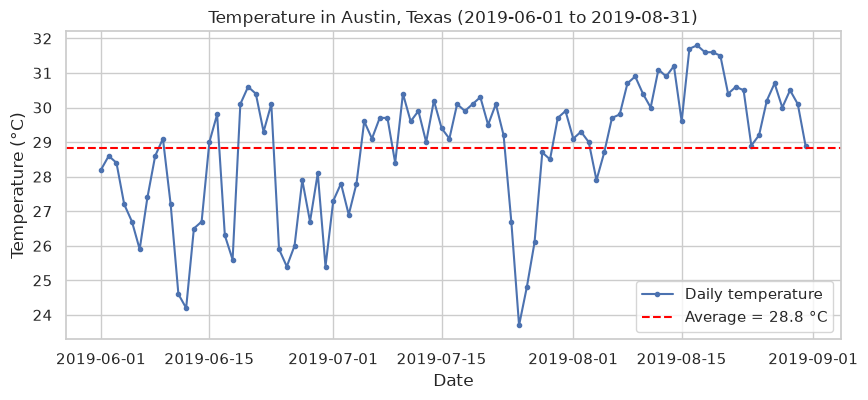

In [8]:
plt.figure(figsize=(10, 4))
# a new chart
plt.plot(selection.index, selection.values, marker='.', label='Daily temperature')
# daily values as a line
plt.axhline(average, color='red', linestyle='--', label=f'Average = {average:.1f} °C')
# horizontal dashed line at the average
plt.title(f'Temperature in {city}, {state} ({start_date} to {end_date})')
# chart title
plt.xlabel('Date')
# x axis label
plt.ylabel('Temperature (°C)')
# y axis label
plt.legend()
# labels box
plt.show()
# show the chart

**How it works:** (1) we put Country, State, City and Date in the index; (2) `.loc[('US', state, city, slice(start, end))]` goes down the levels like folders and cuts the date range; (3) `.mean()` gives the average; (4) a line chart shows each day with the average as a dashed line.

---
# Exercise 3: Dynamic Subplot Configuration with User Interaction
**Objective:** Ask the user how many plots (up to 9), place them in a 3x3 grid, and draw line, scatter, bar and histogram charts with random data.

> **New here: `ipywidgets`.** Tkinter windows don’t work in Colab, so we use a slider from `ipywidgets`. `interact(function, n=slider)` calls our function again every time the slider moves.

In [9]:
def make_subplots(n_plots):
    # draws n_plots small charts in a 3x3 grid
    fig, axes = plt.subplots(3, 3, figsize=(12, 10))
    # a figure with 9 empty boxes (axes)
    axes = axes.flatten()
    # turn the 3x3 grid into a simple list of 9 boxes
    plot_types = ['line', 'scatter', 'bar', 'histogram']
    # the 4 chart types we rotate through
    for i in range(9):
        # go through the 9 boxes
        ax = axes[i]
        # the current box
        if i >= n_plots:
            # boxes we don't need
            ax.axis('off')
            # hide them
            continue
            # go to the next box
        kind = plot_types[i % 4]
        # 0->line, 1->scatter, 2->bar, 3->histogram, then again
        if kind == 'line':
            ax.plot(np.arange(10), np.random.rand(10), color='green', label='random line')
            # 10 random points joined by a line
        elif kind == 'scatter':
            ax.scatter(np.random.rand(20), np.random.rand(20), color='purple', label='random points')
            # 20 random dots
        elif kind == 'bar':
            ax.bar(['A', 'B', 'C', 'D'], np.random.randint(1, 10, 4), color='orange', label='random bars')
            # 4 bars with random heights
        else:
            ax.hist(np.random.randn(200), bins=15, color='steelblue', label='random normal data')
            # histogram of 200 normal random numbers
        ax.set_title(f'Plot {i + 1}: {kind}')
        # title of this box
        ax.set_xlabel('x')
        # x label
        ax.set_ylabel('y')
        # y label
        ax.legend(fontsize=8)
        # small legend
    plt.tight_layout()
    # stop the boxes overlapping
    plt.show()
    # show the figure

In [10]:
import ipywidgets as widgets
# widgets: sliders, dropdowns etc. inside the notebook
from ipywidgets import interact
# interact: links a widget to a function
np.random.seed(1)
# same random data each run
slider = widgets.IntSlider(min=1, max=9, value=6, description='Plots:')
# slider for choosing 1 to 9 plots
interact(make_subplots, n_plots=slider);
# move the slider and the charts redraw

interactive(children=(IntSlider(value=6, description='Plots:', max=9, min=1), Output()), _dom_classes=('widget…

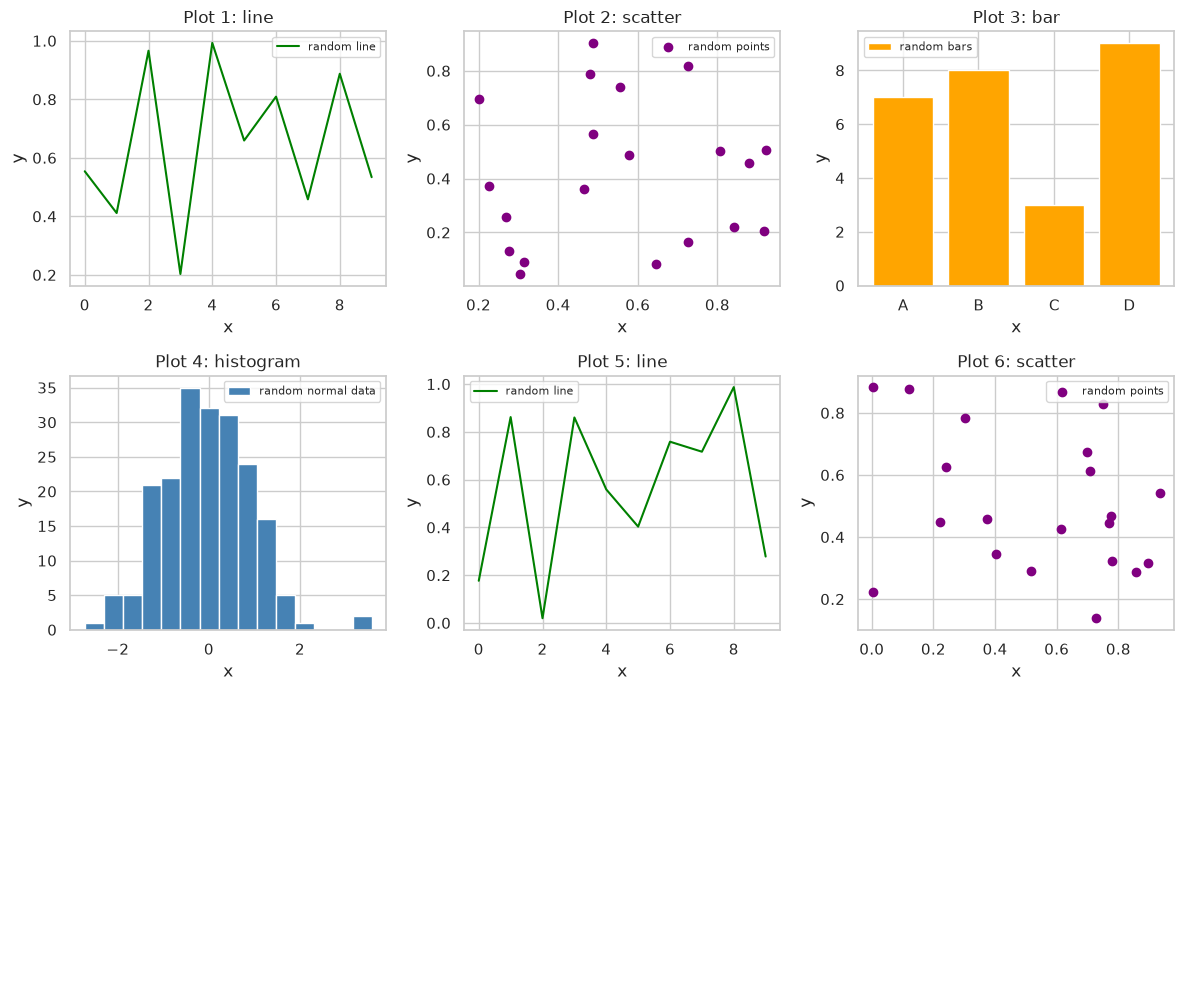

In [11]:
make_subplots(6)
# a fixed example (so the charts also show in a saved/static notebook)

Without widgets you can use `input()` instead (uncomment to try):

In [12]:
# n = int(input('How many plots (1-9)? '))
# ask the user for a number
# make_subplots(min(max(n, 1), 9))
# keep it between 1 and 9 and draw

---
## Load the wine dataset (Exercises 4–6)

In [ ]:
from google.colab import files
# the Colab tool for uploading files from your computer
uploaded = files.upload()
# choose "Wine Price on Polish Market.zip" (saved in a variable so its contents are not printed)
!unzip "Wine Price on Polish Market.zip"
# unzip it: you get the file "wine.csv"

In [13]:
wine = pd.read_csv('wine.csv')
# read the wine file
print(wine.shape)
# rows and columns
wine[['name', 'price (PLN)', 'country', 'vintage', 'alcohol (%)', 'color']].head()
# the columns we use most

(2247, 19)


,name,price (PLN),country,vintage,alcohol (%),color
0,Szampan Moet & Chandon Brut Imperial Magnum w ...,666.0,France,NaN,NaN,NaN
1,11 Filari Primitivo di Manduria San Marzano,109.0,Italy,2017.0,17.5,red
2,Szampan Moet & Chandon Brut Imperial Jeroboam ...,1999.0,France,NaN,NaN,NaN
3,770 Miles Zinfandel California,37.0,United States of America,2021.0,13.5,red
4,770 Miles Zinfandel Rose California,39.0,United States of America,2021.0,10.0,rose


---
# Exercise 4: Multi-Dimensional Analysis of Wine Characteristics
**Objective:** Top 5 countries; average price and alcohol per country and vintage; `FacetGrid` of scatter plots (x = vintage, y = average price, point size = alcohol).

In [14]:
top5 = wine['country'].value_counts().head(5).index
# the 5 countries with the most wines
print(list(top5))
# show them
wine_top = wine[wine['country'].isin(top5)].dropna(subset=['vintage', 'price (PLN)', 'alcohol (%)'])
# keep those countries, and only rows that have vintage, price and alcohol
grouped = wine_top.groupby(['country', 'vintage'])[['price (PLN)', 'alcohol (%)']].mean().reset_index()
# average price and alcohol for each country + vintage
grouped = grouped[grouped['vintage'] >= 2000]
# keep vintages from 2000 so the x axis is readable
grouped.head()
# first rows

['Italy', 'France', 'Spain', 'Austria', 'Poland']


,country,vintage,price (PLN),alcohol (%)
0,Austria,2006.0,249.000000,13.500000
1,Austria,2015.0,151.666667,12.500000
2,Austria,2017.0,139.800000,12.900000
3,Austria,2018.0,165.900000,12.222222
4,Austria,2019.0,152.100000,12.400000


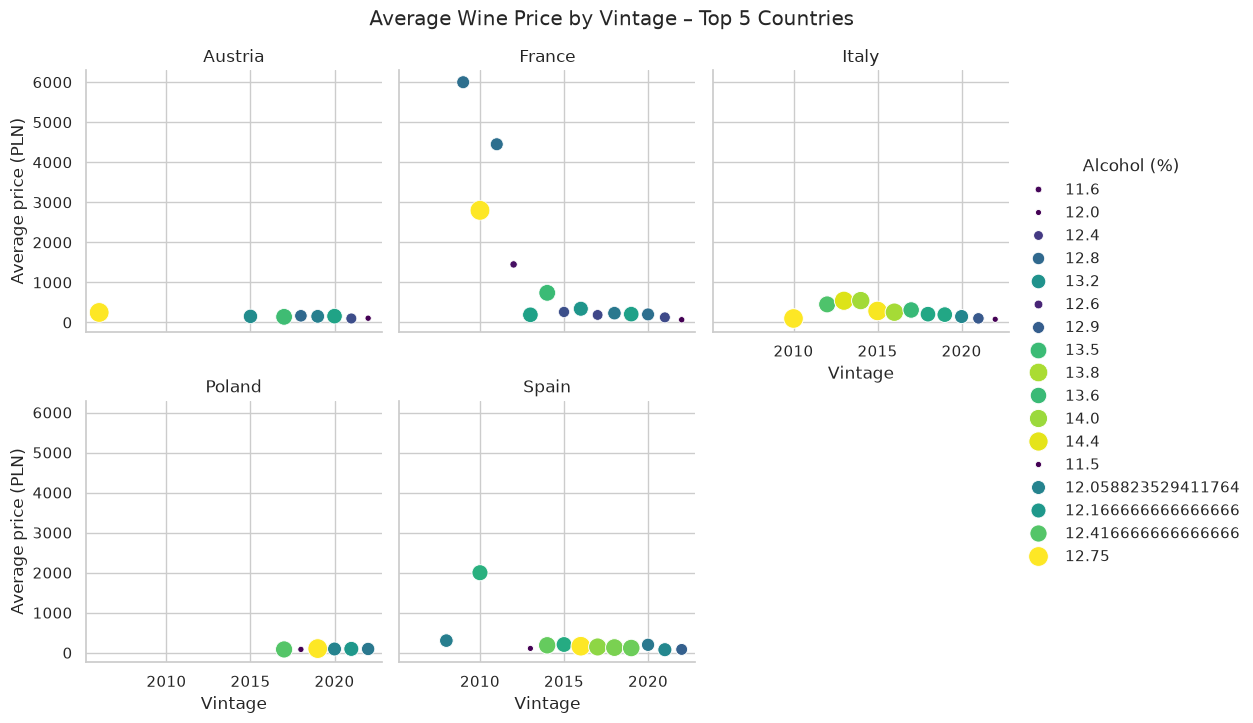

In [15]:
g = sns.FacetGrid(grouped, col='country', col_wrap=3, height=3.5)
# one small chart per country, 3 per row
g.map_dataframe(sns.scatterplot, x='vintage', y='price (PLN)', size='alcohol (%)', sizes=(20, 200), hue='alcohol (%)', palette='viridis')
# in each chart: x = vintage, y = average price, dot size & color = alcohol %
g.add_legend(title='Alcohol (%)')
# legend for the dot sizes/colors
g.set_axis_labels('Vintage', 'Average price (PLN)')
# axis labels for all charts
g.set_titles('{col_name}')
# each small chart gets the country as title
g.figure.suptitle('Average Wine Price by Vintage – Top 5 Countries', y=1.03)
# main title
plt.show()
# show the charts

**What we see:** for every country, older vintages are usually more expensive (aged wines), and recent vintages are cheap and close together.

---
# Exercise 5: Predicting Wine Prices with Machine Learning
> **New here: scikit-learn.** A library for machine learning. We use 4 tools from it: `train_test_split` (split data into a training part and a test part), `RandomForestRegressor` (a model that learns to predict a number from many small decision trees), and `mean_squared_error` / `r2_score` (how good the predictions are). `pd.get_dummies` (pandas) turns text categories into 0/1 columns, because models only understand numbers.

In [16]:
from sklearn.model_selection import train_test_split
# to split the data into train and test
from sklearn.ensemble import RandomForestRegressor
# the prediction model
from sklearn.metrics import mean_squared_error, r2_score
# to measure how good the model is

In [17]:
ml = wine[['price (PLN)', 'vintage', 'alcohol (%)', 'volume (liters)', 'country', 'color', 'taste']].copy()
# the columns we use: price (target) + some features
ml = ml.dropna(subset=['price (PLN)'])
# a row without a price can't be used
for col in ['vintage', 'alcohol (%)', 'volume (liters)']:
    # the number columns
    ml[col] = ml[col].fillna(ml[col].median())
    # fill missing numbers with the middle value (median)
for col in ['country', 'color', 'taste']:
    # the text columns
    ml[col] = ml[col].fillna('unknown')
    # fill missing text with 'unknown'
ml = ml[ml['price (PLN)'] < ml['price (PLN)'].quantile(0.99)]
# drop the 1% most expensive wines (extreme prices confuse the model)
X = pd.get_dummies(ml.drop(columns='price (PLN)'), columns=['country', 'color', 'taste'])
# features: text columns turned into 0/1 columns
y = ml['price (PLN)']
# target: the price
print(X.shape)
# how many rows and feature columns

(2224, 39)


Note: a random forest does not need normalized features, so we skip that step here (we normalize in Exercise 6).

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# 80% of rows to learn, 20% to test
model = RandomForestRegressor(n_estimators=200, random_state=42)
# a forest of 200 trees
model.fit(X_train, y_train)
# learn from the training data
y_pred = model.predict(X_test)
# predict prices for the test wines
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
# RMSE: typical size of the error, in PLN
r2 = r2_score(y_test, y_pred)
# R²: 1 = perfect, 0 = no better than guessing the average
print(f'RMSE: {rmse:.1f} PLN')
# show RMSE
print(f'R²: {r2:.2f}')
# show R²

RMSE: 186.8 PLN
R²: 0.18


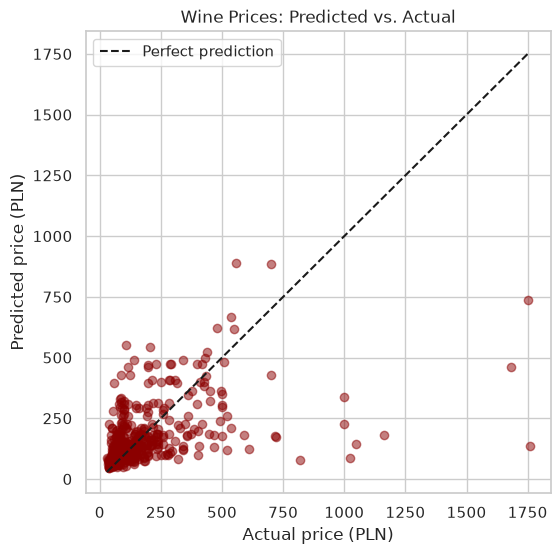

In [19]:
plt.figure(figsize=(6, 6))
# a square chart
plt.scatter(y_test, y_pred, alpha=0.5, color='darkred')
# one dot per test wine: real price vs predicted price
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', label='Perfect prediction')
# diagonal line: where dots would be if predictions were perfect
plt.xlabel('Actual price (PLN)')
# x label
plt.ylabel('Predicted price (PLN)')
# y label
plt.title('Wine Prices: Predicted vs. Actual')
# title
plt.legend()
# legend
plt.show()
# show the chart

**Result:** R² is low (about 0.2): the model catches only a small part of the price differences and misses a lot on single wines – price depends on things not in our columns (brand, reputation, region).

---
# Exercise 6: Clustering Analysis to Identify Similar Wines
> **New here:** `StandardScaler` (puts all features on the same scale), `KMeans` (groups similar rows into k clusters), `silhouette_score` (how well separated the clusters are, closer to 1 = better) and `PCA` (squeezes many columns into 2 so we can draw them). All from scikit-learn.

In [20]:
from sklearn.preprocessing import StandardScaler
# normalizes features
from sklearn.cluster import KMeans
# the clustering model
from sklearn.metrics import silhouette_score
# cluster quality score
from sklearn.decomposition import PCA
# reduce to 2 dimensions for plotting

In [21]:
features = ['price (PLN)', 'vintage', 'alcohol (%)', 'volume (liters)']
# the number columns we group wines by
cl = ml[features]
# reuse the cleaned data from Exercise 5 (no missing values)
X_scaled = StandardScaler().fit_transform(cl)
# each column now has mean 0 and std 1, so price doesn't dominate
inertias = []
# list for the elbow method
silhouettes = []
# list for silhouette scores
k_values = range(2, 9)
# try 2 to 8 clusters
for k in k_values:
    # one model per k
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    # make the model
    labels = km.fit_predict(X_scaled)
    # fit it and get the cluster of each wine
    inertias.append(km.inertia_)
    # inertia = how spread the clusters are (smaller = tighter)
    silhouettes.append(silhouette_score(X_scaled, labels))
    # silhouette for this k

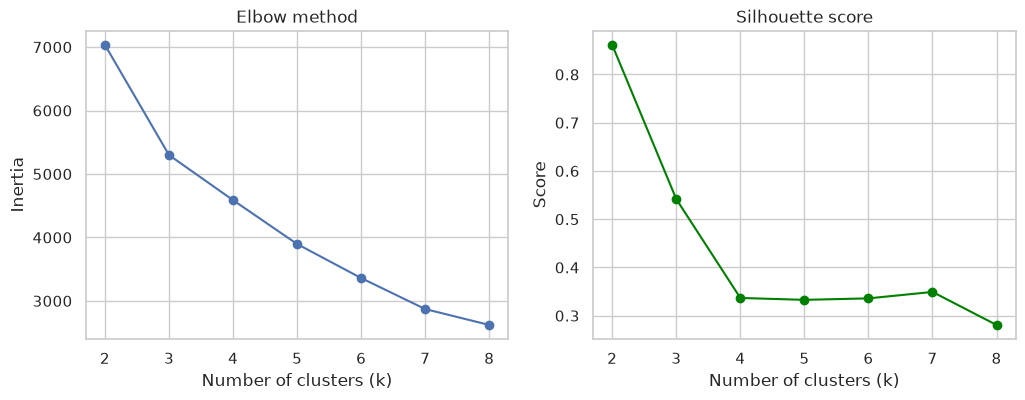

Best k by silhouette: 2


In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
# two charts side by side
ax1.plot(k_values, inertias, marker='o')
# elbow chart
ax1.set_title('Elbow method')
# title
ax1.set_xlabel('Number of clusters (k)')
# x label
ax1.set_ylabel('Inertia')
# y label
ax2.plot(k_values, silhouettes, marker='o', color='green')
# silhouette chart
ax2.set_title('Silhouette score')
# title
ax2.set_xlabel('Number of clusters (k)')
# x label
ax2.set_ylabel('Score')
# y label
plt.show()
# show both
best_k = list(k_values)[int(np.argmax(silhouettes))]
# the k with the highest silhouette score
print('Best k by silhouette:', best_k)
# show it

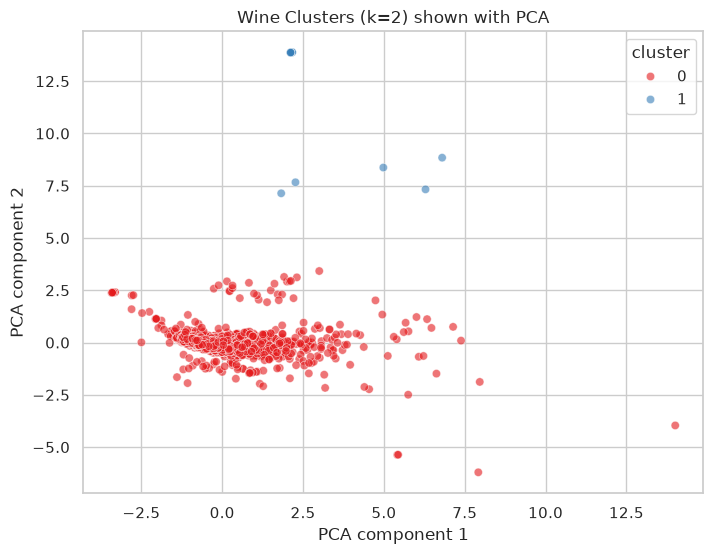

In [23]:
km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
# final model with the best k
cl = cl.copy()
# a copy so we can add a column safely
cl['cluster'] = km.fit_predict(X_scaled)
# the cluster number of each wine
points = PCA(n_components=2).fit_transform(X_scaled)
# 4 columns -> 2 columns, only for drawing
plt.figure(figsize=(8, 6))
# a new chart
sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=cl['cluster'], palette='Set1', alpha=0.6)
# one dot per wine, colored by cluster
plt.title(f'Wine Clusters (k={best_k}) shown with PCA')
# title
plt.xlabel('PCA component 1')
# x label
plt.ylabel('PCA component 2')
# y label
plt.show()
# show the chart

In [24]:
cl.groupby('cluster')[features].mean().round(1)
# the average wine of each cluster, to describe the groups

,price (PLN),vintage,alcohol (%),volume (liters)
cluster,,,,
0,164.9,2019.2,13.1,0.8
1,476.3,2019.2,13.2,4.2


In [25]:
cl['cluster'].value_counts().sort_index()
# how many wines are in each cluster

cluster
0    2212
1      12
Name: count, dtype: int64

**Interpretation:** the best silhouette is at k=2. Cluster 1 is a tiny group (12 wines) of big bottles (magnum/jeroboam, ~4 L) that are also much more expensive; cluster 0 is all the normal 0.75 L bottles. So with these 4 number columns, bottle size is what separates wines most clearly; to find finer groups (e.g. by taste or color) we would need to add those columns. This helps a shop group similar wines for recommendations.